In [33]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from scipy.optimize import minimize
import matplotlib.pyplot as plt


In [ ]:
data = pd.DataFrame({
    'lead_time': [10, 25, 30, 12, 40, 15],
    'distance': [1000, 5000, 8000, 1200, 11000, 2000],
    'weather_risk': [0.1, 0.7, 0.9, 0.2, 0.8, 0.3],
    'delayed': [0, 1, 1, 0, 1, 0]  
})

display(data)

Sample Dataset:


,lead_time,distance,weather_risk,delayed
0,10,1000,0.1,0
1,25,5000,0.7,1
2,30,8000,0.9,1
3,12,1200,0.2,0
4,40,11000,0.8,1
5,15,2000,0.3,0


In [35]:
X = data[['lead_time', 'distance', 'weather_risk']]
y = data['delayed']

model = XGBClassifier()
model.fit(X, y)


,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

In [32]:

sample_input = np.array([[35, 9000, 0.85]]) 
pred_prob = model.predict_proba(sample_input)[0][1]

print(f"Predicted Delay Probability: {pred_prob * 100:.1f}%\n")

if pred_prob > 0.5:
    print(" Alert: High risk of delay detected")
    
    options = [" Air Freight", " Secondary Supplier", "Delay Launch"]
    costs = [15000, 8000, 0]    
    delays = [0, 3, 10]         
    
    df_results = pd.DataFrame({
        'Prescribed Action': options,
        'Estimated Cost ($)': costs,
        'Delay Impact (Days)': delays
    })
    
    display(df_results)
else:
    print(" Shipment is safe ")

Predicted Delay Probability: 50.0%

 Shipment is safe 


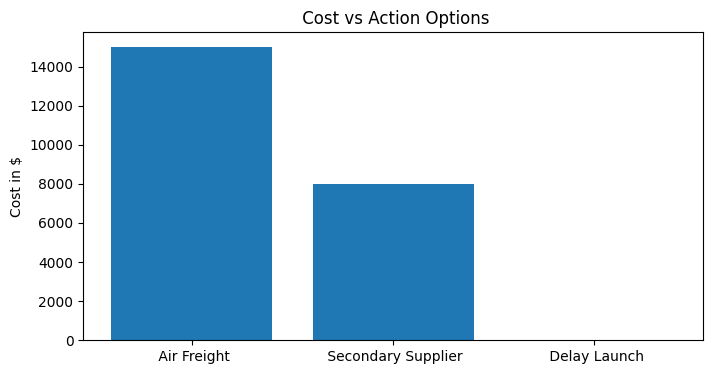

In [34]:
options = [" Air Freight", " Secondary Supplier", " Delay Launch"]
costs = [15000, 8000, 0]

# Creating the plot
plt.figure(figsize=(8, 4))
plt.bar(options, costs)
plt.title(" Cost vs Action Options")
plt.ylabel("Cost in $")
plt.show()